# Khung phân tích hiệu năng mô hình AI — Cấp độ 2

Notebook này khảo sát ảnh hưởng của độ dài prompt, số token sinh ra và kích thước batch, rồi phân tích riêng một lượt chạy mô hình ở giai đoạn xử lý prompt (Prefill) và một lượt ở giai đoạn sinh token (Decode) có dùng bộ nhớ đệm Key-Value (KV cache). Chạy các cell từ trên xuống dưới, tại thư mục gốc của repository và trong môi trường ảo của dự án. Model mặc định: `sshleifer/tiny-gpt2`.

**Phạm vi đo thời gian:** Độ trễ Prefill gồm một lần gọi model với toàn bộ prompt và bước đồng bộ hóa thiết bị. Logits của Prefill cung cấp token sinh đầu tiên, nhưng thao tác chọn token bằng argmax nằm ngoài khoảng đo. Độ trễ mỗi bước Decode gồm một lần gọi model với một token và KV cache từ lần gọi trước; mỗi bước đều đồng bộ hóa sau khi gọi model. Việc mở rộng attention mask và chọn token bằng argmax nằm ngoài khoảng đo. Benchmark cộng thời gian của tất cả bước Decode đã cấu hình. Công cụ phân tích hiệu năng (profiler) ghi dấu vết thực thi (trace) của một lượt chạy mô hình đại diện cho mỗi giai đoạn, sau bước làm nóng (warm-up) riêng. Thời gian tải model, tokenization và chi phí của profiler nằm ngoài thời gian benchmark.

Vòng lặp chọn token theo greedy argmax và luôn sinh đủ số token yêu cầu, kể cả sau EOS. `decode_steps_per_s` giữ cách tính số lượt gọi mỗi giây, không phụ thuộc kích thước batch, của Cấp độ 1. `decode_tokens_per_s` và `end_to_end_tokens_per_s` đếm token trên toàn batch. Đây là tốc độ chạy model, không phải tốc độ sinh văn bản mà người dùng trực tiếp cảm nhận.

## Thiết lập và chọn cấu hình tải thử nghiệm

Cài đặt bằng `pip install -e .`. Lần tải model đầu tiên có thể cần Internet. `WORKLOADS` chọn các lượt quét chỉ thay đổi một biến; chương trình **không** chạy mọi tổ hợp của tích Descartes. Sửa các danh sách và hằng số nếu cần thí nghiệm lớn hơn. `workload_plan.csv` ghi các tổ hợp tham số được chọn và cố ý bỏ qua, gồm mọi lượt quét có nhãn của từng tổ hợp đã chọn. Mỗi batch chứa các prompt giống nhau, không padding, nên mọi vị trí trong attention mask đều là token thật. Mỗi phép đo thô có `run_id`; kết quả từ các lần chạy khác nhau không được xem là so sánh có kiểm soát.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display
from transformers import AutoModelForCausalLM, AutoTokenizer

# Nạp lại các thay đổi trong module hỗ trợ khi chạy lại cell ở kernel hiện tại.
import importlib
import profiling_mvp.level2 as level2_module
importlib.reload(level2_module)
from profiling_mvp.level2 import (Workload, benchmark_workloads, build_report,
    choose_device, comparison_issues, make_workload_matrix, metadata, profile_phase, rank_operators, summarize_workloads)

MODEL_NAME = "sshleifer/tiny-gpt2"
DEVICE_REQUESTED = "mps"  # auto, cpu, mps, cuda
SEED = 1234
WARMUP = 1
REPEATS = 3
PROMPT_LENGTHS = [32, 64, 128]  # thêm 256 nếu đủ thời gian và bộ nhớ
GENERATION_LENGTHS = [8, 16, 32]  # thêm 64 nếu đủ thời gian
BATCH_SIZES = [1, 2]
BASE_PROMPT = 64
BASE_NEW_TOKENS = 8
DECODE_CONTEXT_STEPS = 0  # các lượt chạy thêm với cache, nằm ngoài profiler
OUTPUT_DIR = Path("results/notebook_level2")
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
TRACE_DIR = OUTPUT_DIR / "traces" / RUN_ID
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TRACE_DIR.mkdir(parents=True, exist_ok=True)

WORKLOADS, workload_plan_df = make_workload_matrix(
    PROMPT_LENGTHS, GENERATION_LENGTHS, BATCH_SIZES, BASE_PROMPT, BASE_NEW_TOKENS
)
PROFILE_WORKLOADS = [Workload("representative", BASE_PROMPT, BASE_NEW_TOKENS, 1)]
workload_plan_df.to_csv(OUTPUT_DIR / "workload_plan.csv", index=False)
DEVICE = choose_device(DEVICE_REQUESTED)
torch.manual_seed(SEED)
if DEVICE == "cuda":
    torch.cuda.manual_seed_all(SEED)
print(f"Thiết bị: {DEVICE}; số workload benchmark: {len(WORKLOADS)}; số workload profiler: {len(PROFILE_WORKLOADS)}")
display(pd.DataFrame([vars(w) for w in WORKLOADS]))

Thiết bị: mps; số workload benchmark: 8; số workload profiler: 1


,experiment,prompt_tokens,max_new_tokens,batch_size
0,prompt_length,32,8,1
1,prompt_length,64,8,1
2,prompt_length,128,8,1
3,generation_length,64,8,1
4,generation_length,64,16,1
5,generation_length,64,32,1
6,batch_size,64,8,1
7,batch_size,64,8,2


## Tải model một lần

Model và tokenizer được dùng lại. Thời gian tải model nằm ngoài mọi khoảng đo. Nếu tải thất bại, notebook dừng tại đây và giữ nguyên thông báo lỗi gốc.

In [2]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME).to(DEVICE).eval()
print("Đã tải model:", MODEL_NAME)

Loading weights:   0%|          | 0/29 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: sshleifer/tiny-gpt2
Key                                   | Status     |  | 
--------------------------------------+------------+--+-
transformer.h.{0, 1}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Đã tải model: sshleifer/tiny-gpt2


## Benchmark thông thường

Mỗi cấu hình tải thử nghiệm (workload) có bước làm nóng riêng. Việc thực thi trên thiết bị được đồng bộ hóa quanh mỗi lượt chạy mô hình. Mỗi lần đo theo kế hoạch có một dòng trong `raw_runs.csv`. Cấu hình không hợp lệ mang trạng thái `unsupported`; lỗi khi chuẩn bị hoặc làm nóng khiến các lần đo dự kiến mang trạng thái `skipped`; lỗi trong lúc đo mang trạng thái `failed`. Mỗi trạng thái đều có lý do. Các lượt làm nóng không được ghi vào bảng. Chỉ các lần đo thành công được đưa vào tóm tắt số liệu; số lượng và trạng thái lỗi vẫn được hiển thị. Nếu chỉ yêu cầu sinh một token thì không có lượt chạy Decode: độ trễ và tốc độ Decode không có giá trị. Thời lượng đo không hữu hạn hoặc không dương khiến lần đo thất bại. `prompt_tokens_per_s` lấy tổng số token prompt trong batch chia cho thời gian Prefill. Vì Prefill còn tính logits, đây là tốc độ xử lý prompt, không phải thông lượng tokenization.

In [3]:
raw_df = benchmark_workloads(model, tokenizer, WORKLOADS, DEVICE, WARMUP, REPEATS, run_id=RUN_ID)
assert len(raw_df) == len(WORKLOADS) * REPEATS
summary_df, stability_df = summarize_workloads(raw_df)
raw_df.to_csv(OUTPUT_DIR / "raw_runs.csv", index=False)
summary_df.to_csv(OUTPUT_DIR / "workload_summary.csv", index=False)
stability_df.to_csv(OUTPUT_DIR / "stability_summary.csv", index=False)
display(summary_df[["workload", "status", "runs_ok", "runs_failed", "runs_skipped", "runs_unsupported", "errors",
    "prefill_latency_s_median", "decode_latency_s_median", "decode_tokens_per_s_median"]])

,workload,status,runs_ok,runs_failed,runs_skipped,runs_unsupported,errors,prefill_latency_s_median,decode_latency_s_median,decode_tokens_per_s_median
0,prompt_length_p32_n8_b1,ok,3,0,0,0,None,0.004252,0.018318,382.131717
1,prompt_length_p64_n8_b1,ok,3,0,0,0,None,0.003028,0.011167,626.844601
2,prompt_length_p128_n8_b1,ok,3,0,0,0,None,0.004163,0.011640,601.359641
3,generation_length_p64_n8_b1,ok,3,0,0,0,None,0.002934,0.012896,542.796983
4,generation_length_p64_n16_b1,ok,3,0,0,0,None,0.003856,0.031377,478.059051
5,generation_length_p64_n32_b1,ok,3,0,0,0,None,0.003607,0.053824,575.950778
6,batch_size_p64_n8_b1,ok,3,0,0,0,None,0.002368,0.009930,704.910828
7,batch_size_p64_n8_b2,ok,3,0,0,0,None,0.004314,0.026262,533.082023


## Lượt phân tích operator riêng

Mỗi lần chạy dùng một thư mục con trace duy nhất. Chỉ các đường dẫn trong `profile_runs.json` thuộc bộ kết quả hiện tại. Mỗi trace chứa **một lượt chạy mô hình**. Prefill bắt đầu từ toàn bộ prompt. Decode tạo KV cache trước, ngoài profiler; lượt chạy được phân tích nhận một token và cache đó. `DECODE_CONTEXT_STEPS` có thể tăng độ dài ngữ cảnh trong cache trước khi ghi trace. Vì vậy, tổng thời gian operator mô tả một lượt chạy tại vị trí ngữ cảnh ấy, không phải toàn bộ quá trình sinh token. Chi phí profiling không đi vào `raw_runs.csv`.

Hoạt động CPU có trên mọi backend được hỗ trợ. Hoạt động CUDA chỉ được yêu cầu khi dùng CUDA. Với MPS, notebook ghi thời gian operator ở phía CPU do PyTorch cung cấp; đây **không phải thời gian thực thi trên thiết bị MPS**. Trường không có dữ liệu giữ giá trị null. `operator_summary.csv` giữ riêng các nhóm theo hình dạng đầu vào; báo cáo và biểu đồ xếp hạng cộng thời gian CPU riêng của từng operator qua các nhóm đó. Các trường bộ nhớ của PyTorch profiler mô tả sự kiện của bộ cấp phát, không phải bộ nhớ vật lý cực đại.

In [4]:
operator_rows = []
profile_runs = []
for workload in PROFILE_WORKLOADS:
    for phase in ("prefill", "decode"):
        rows, info = profile_phase(model, tokenizer, workload, phase, DEVICE,
                                   TRACE_DIR, DECODE_CONTEXT_STEPS)
        operator_rows.extend(rows)
        profile_runs.append(info)
        print(workload.name, phase, info["status"], info.get("error") or info.get("trace"))
operator_df = pd.DataFrame(operator_rows, columns=["workload", "phase", "device", "operator",
    "input_shapes", "cpu_calls", "self_cpu_time_us", "total_cpu_time_us",
    "self_device_time_us", "total_device_time_us", "device_calls",
    "cpu_memory_bytes", "self_cpu_memory_bytes", "device_memory_bytes",
    "self_device_memory_bytes", "trace"])
operator_df.to_csv(OUTPUT_DIR / "operator_summary.csv", index=False)
(OUTPUT_DIR / "profile_runs.json").write_text(json.dumps(profile_runs, indent=2), encoding="utf-8")
if len(operator_df):
    display(operator_df.sort_values("self_cpu_time_us", ascending=False).head(12))

representative_p64_n8_b1 prefill ok results/notebook_level2/traces/20261016T001619555560Z/representative_p64_n8_b1_prefill_mps.json
representative_p64_n8_b1 decode ok results/notebook_level2/traces/20261016T001619555560Z/representative_p64_n8_b1_decode_mps.json


USDT:2026-10-16 07:16:23 84044:7979313 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-10-16 07:16:23 84044:7979313 SyncActivityProfilerHandler.cpp:46] profiler_stop
USDT:2026-10-16 07:16:23 84044:7979313 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-10-16 07:16:23 84044:7979313 SyncActivityProfilerHandler.cpp:46] profiler_stop


,workload,phase,device,operator,input_shapes,cpu_calls,self_cpu_time_us,total_cpu_time_us,self_device_time_us,total_device_time_us,device_calls,cpu_memory_bytes,self_cpu_memory_bytes,device_memory_bytes,self_device_memory_bytes,trace
0,representative_p64_n8_b1,prefill,mps,model_forward_prefill,[],1,1407.524,3440.357,None,None,None,0,0,None,None,results/notebook_level2/traces/20261016T001619...
89,representative_p64_n8_b1,decode,mps,model_forward_decode,[],1,467.628,1411.583,None,None,None,0,0,None,None,results/notebook_level2/traces/20261016T001619...
117,representative_p64_n8_b1,decode,mps,aten::_local_scalar_dense,[[]],1,404.958,406.458,None,None,None,0,-1,None,None,results/notebook_level2/traces/20261016T001619...
27,representative_p64_n8_b1,prefill,mps,aten::_local_scalar_dense,[[]],1,379.840,381.799,None,None,None,0,-1,None,None,results/notebook_level2/traces/20261016T001619...
8,representative_p64_n8_b1,prefill,mps,aten::arange,"[[], [], [], [], []]",1,261.005,278.422,None,None,None,0,0,None,None,results/notebook_level2/traces/20261016T001619...
52,representative_p64_n8_b1,prefill,mps,aten::_scaled_dot_product_attention_math_for_mps,"[[1, 2, 64, 1], [1, 2, 64, 1], [1, 2, 64, 1], ...",2,243.880,250.922,None,None,None,0,0,None,None,results/notebook_level2/traces/20261016T001619...
140,representative_p64_n8_b1,decode,mps,aten::_scaled_dot_product_attention_math_for_mps,"[[1, 2, 1, 1], [1, 2, 65, 1], [1, 2, 65, 1], [...",2,241.543,244.001,None,None,None,0,0,None,None,results/notebook_level2/traces/20261016T001619...
18,representative_p64_n8_b1,prefill,mps,aten::_to_copy,"[[1, 64], [], [], [], [], [], []]",1,202.794,214.629,None,None,None,0,0,None,None,results/notebook_level2/traces/20261016T001619...
34,representative_p64_n8_b1,prefill,mps,aten::addmm,"[[6], [64, 2], [2, 6], [], []]",2,179.337,184.796,None,None,None,0,0,None,None,results/notebook_level2/traces/20261016T001619...
62,representative_p64_n8_b1,prefill,mps,aten::addmm,"[[2], [64, 2], [2, 2], [], []]",2,98.877,101.377,None,None,None,0,0,None,None,results/notebook_level2/traces/20261016T001619...


## Biểu đồ theo cấu hình tải thử nghiệm

Mọi điểm trên biểu đồ là trung vị của các lần đo thành công. Theo mặc định, lượt quét độ dài prompt và số token sinh ra dùng kích thước batch bằng 1. Lượt quét kích thước batch mặc định giữ cố định độ dài prompt và số token sinh ra; thông lượng đếm token sinh trên tất cả chuỗi. Biểu đồ cho thấy mối liên hệ trong cấu hình đã chọn, không chứng minh nguyên nhân từ phần cứng. Lượt quét tùy chỉnh có thể thay đổi thêm tham số khác; `report.md` nêu các khác biệt đó và không đưa ra so sánh có kiểm soát.

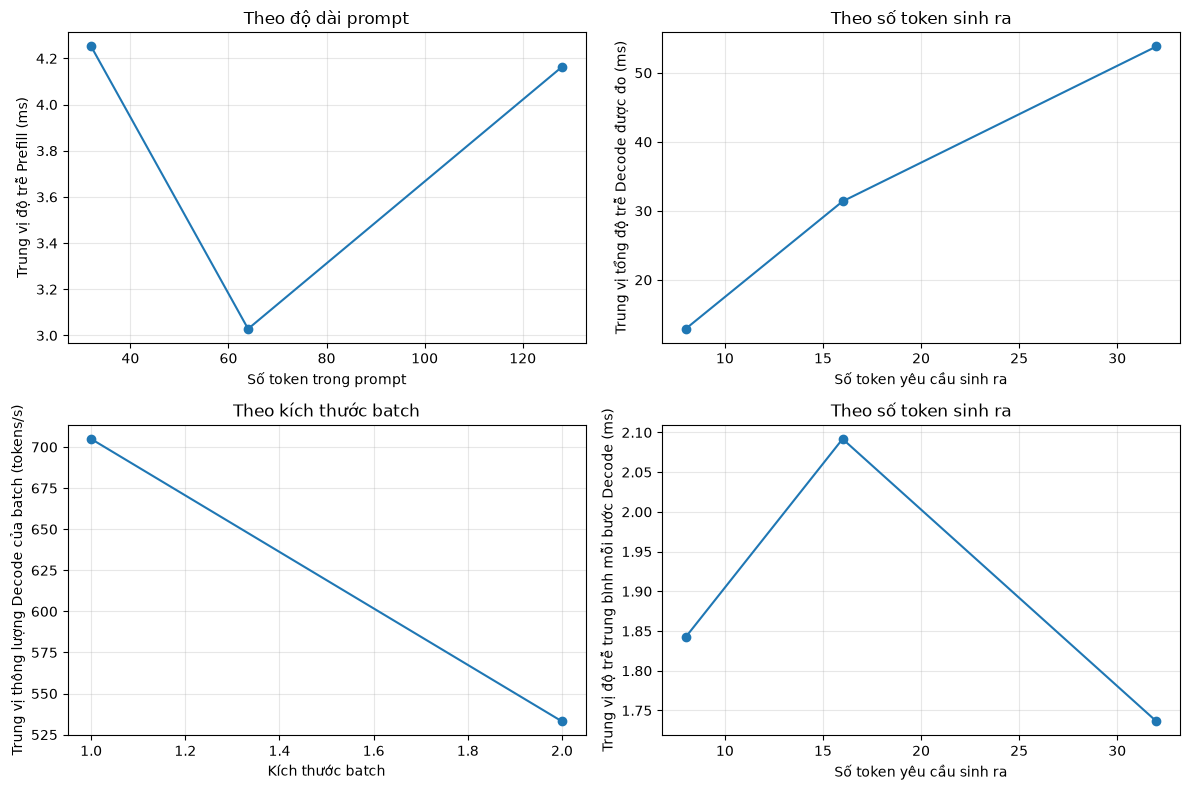

In [5]:
def valid_sweep(experiment):
    data = summary_df[(summary_df.experiment == experiment) & (summary_df.runs_ok > 0)].copy()
    if data.empty:
        print(f"Không có dòng đo thành công cho {experiment}")
    return data

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
plots = [
    ("prompt_length", "prompt_tokens", "prefill_latency_s_median", 1000,
     "Số token trong prompt", "Trung vị độ trễ Prefill (ms)"),
    ("generation_length", "max_new_tokens", "decode_latency_s_median", 1000,
     "Số token yêu cầu sinh ra", "Trung vị tổng độ trễ Decode được đo (ms)"),
    ("batch_size", "batch_size", "decode_tokens_per_s_median", 1,
     "Kích thước batch", "Trung vị thông lượng Decode của batch (tokens/s)"),
    ("generation_length", "max_new_tokens", "decode_step_latency_mean_s_median", 1000,
     "Số token yêu cầu sinh ra", "Trung vị độ trễ trung bình mỗi bước Decode (ms)"),
]
for ax, (experiment, x, y, factor, xlabel, ylabel) in zip(axes.flat, plots):
    data = valid_sweep(experiment).sort_values(x)
    if not data.empty:
        ax.plot(data[x], data[y] * factor, marker="o")
    mixed = bool(comparison_issues(data, x)) if len(data) else False
    title = {"prompt_length": "Theo độ dài prompt", "generation_length": "Theo số token sinh ra", "batch_size": "Theo kích thước batch"}[experiment] + (" (tham số kiểm soát thay đổi)" if mixed else "")
    ax.set(xlabel=xlabel, ylabel=ylabel, title=title)
    ax.grid(alpha=.3)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "workload_plots.png", dpi=150)
plt.show()

## Xếp hạng và so sánh operator

Biểu đồ dùng phần tử đầu tiên của `PROFILE_WORKLOADS`. Xếp hạng operator (phép toán cấp thấp) `aten::` và `prim::` theo **thời gian CPU riêng của operator, cộng qua các nhóm hình dạng đầu vào**; thời gian này không gồm thời gian của operator lồng bên trong. Tổng thời gian CPU của mỗi operator có tính cả phần lồng nhau, nên các khoảng thời gian chồng lấn; không cộng chúng để ước tính độ trễ. Thời gian riêng trên thiết bị CUDA chỉ xuất hiện nếu hoạt động CUDA của profiler thành công. Profiler cũng gây thêm chi phí, vì vậy chỉ so sánh cơ cấu operator; không đối chiếu trực tiếp các thời gian này với độ trễ benchmark đo theo đồng hồ thực.

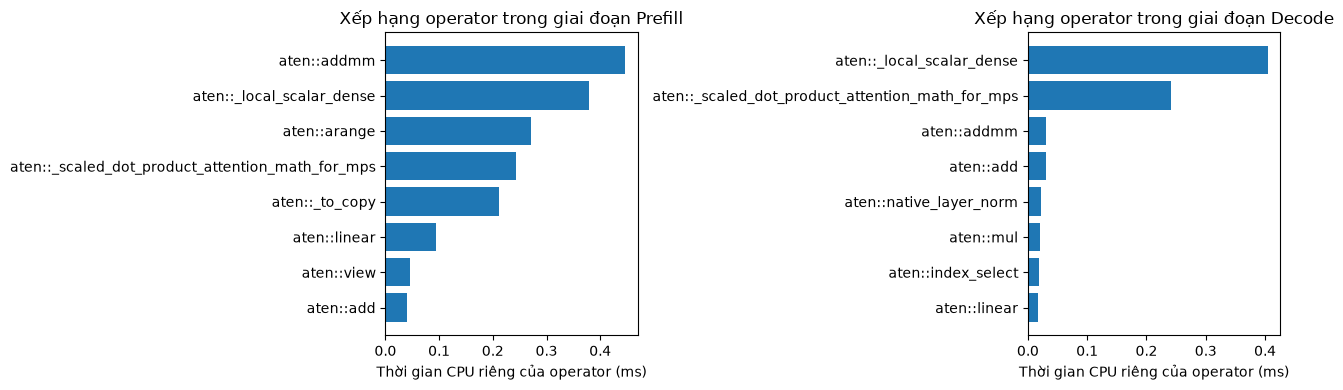

,workload,prefill_latency_s_median,decode_latency_s_median,decode_tokens_per_s_median,end_to_end_tokens_per_s_median
0,prompt_length_p32_n8_b1,0.004252,0.018318,382.131717,363.752811
1,prompt_length_p64_n8_b1,0.003028,0.011167,626.844601,563.558874
2,prompt_length_p128_n8_b1,0.004163,0.011640,601.359641,506.218388
3,generation_length_p64_n8_b1,0.002934,0.012896,542.796983,505.372233
4,generation_length_p64_n16_b1,0.003856,0.031377,478.059051,459.195541
5,generation_length_p64_n32_b1,0.003607,0.053824,575.950778,557.189534
6,batch_size_p64_n8_b1,0.002368,0.009930,704.910828,646.802236
7,batch_size_p64_n8_b2,0.004314,0.026262,533.082023,515.387805


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, phase in zip(axes, ("prefill", "decode")):
    workload_name = PROFILE_WORKLOADS[0].name
    top = rank_operators(operator_df, workload_name, phase).head(8).sort_values("self_cpu_time_us")
    if not top.empty:
        ax.barh(top.operator, top.self_cpu_time_us / 1000)
    ax.set(xlabel="Thời gian CPU riêng của operator (ms)", title=f"Xếp hạng operator trong giai đoạn {phase.title()}")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "operator_rankings.png", dpi=150, bbox_inches="tight")
plt.show()

comparison = summary_df.loc[summary_df.runs_ok > 0,
    ["workload", "prefill_latency_s_median", "decode_latency_s_median",
     "decode_tokens_per_s_median", "end_to_end_tokens_per_s_median"]]
display(comparison)

## Lưu metadata và báo cáo bằng chứng

`report.md` phân biệt **Quan sát** từ phép đo trực tiếp, **Diễn giải** có cơ sở và **Giả thuyết chưa kiểm chứng** cần thêm bằng chứng. Báo cáo không chẩn đoán băng thông, cache hay tình trạng đình trệ phần cứng.

In [7]:
run_metadata = metadata(MODEL_NAME, tokenizer, DEVICE, SEED, WORKLOADS,
    PROFILE_WORKLOADS, WARMUP, REPEATS, DECODE_CONTEXT_STEPS, profile_runs, model=model)
run_metadata["run_id"] = RUN_ID
run_metadata["workload_plan"] = workload_plan_df.to_dict(orient="records")
(OUTPUT_DIR / "metadata.json").write_text(json.dumps(run_metadata, indent=2, default=str), encoding="utf-8")
report = build_report(run_metadata, summary_df, stability_df, operator_df, profile_runs)
# Chỉ dịch văn bản trình bày; giữ nguyên số liệu, tên metric và key dữ liệu.
report_labels_vi = [
    ("# Level 2 profiling report", "# Báo cáo phân tích hiệu năng Cấp độ 2"),
    ("## Method", "## Phương pháp"),
    ("## Workloads and observed measurements", "## Cấu hình tải và kết quả đo"),
    ("## Changes within controlled sweeps", "## Thay đổi trong các lượt quét có kiểm soát"),
    ("## Repeatability", "## Khả năng tái lập"),
    ("## Operator rankings", "## Xếp hạng operator"),
    ("## Interpretation and limits", "## Diễn giải và giới hạn"),
    ("**Unverified hypothesis:**", "**Giả thuyết chưa kiểm chứng:**"),
    ("**Interpretation:**", "**Diễn giải:**"),
    ("**Observed:**", "**Quan sát:**"),
    ("Run: ", "Lần chạy: "),
    ("Model: ", "Model: "),
    ("; revision: ", "; phiên bản: "),
    ("; device: ", "; thiết bị: "),
    (" warm-up and ", " lượt làm nóng và "),
    (" measured runs per workload.", " lần đo cho mỗi workload."),
    ("Tokenization, model loading, and profiling are outside benchmark timing.", "Thời gian tokenization, tải model và profiling nằm ngoài khoảng đo benchmark."),
    ("Prefill includes the first generated token's model forward.", "Prefill gồm lượt chạy model để tạo token đầu tiên."),
    ("Each timed region includes the Python model call and device synchronization.", "Mỗi khoảng đo gồm lệnh gọi model từ Python và bước đồng bộ hóa thiết bị."),
    ("Argmax token selection, attention-mask updates, and profiler overhead are excluded.", "Thao tác chọn token bằng argmax, cập nhật attention mask và chi phí profiler đều nằm ngoài khoảng đo."),
    ("Decode times the remaining cached one-token model forwards.", "Decode đo các lượt chạy model còn lại, mỗi lượt một token và có dùng KV cache."),
    ("Batch throughput counts tokens across all sequences.", "Thông lượng batch đếm token trên tất cả chuỗi."),
    ("Prompt rate is aggregate prompt tokens divided by the timed Prefill forward; it includes logits computation, not tokenization.", "Tốc độ xử lý prompt bằng tổng số token prompt chia cho thời gian Prefill; phép đo gồm tính logits, không gồm tokenization."),
    ("The fixed-length greedy loop does not stop at EOS.", "Vòng lặp greedy với độ dài cố định không dừng tại EOS."),
    ("Profiler traces contain one forward per phase; the benchmark times all configured Decode forwards.", "Trace của profiler chứa một lượt chạy mô hình cho mỗi giai đoạn; benchmark đo toàn bộ lượt Decode đã cấu hình."),
    ("Only traces listed in this report belong to this result set; older trace files may remain on disk.", "Chỉ các trace liệt kê trong báo cáo thuộc bộ kết quả này; trace cũ có thể vẫn nằm trên đĩa."),
    (" successful, ", " thành công, "),
    (" failed, ", " thất bại, "),
    (" skipped, ", " bỏ qua, "),
    (" unsupported)", " không hỗ trợ)"),
    (": median prefill ", ": trung vị độ trễ Prefill "),
    ("; decode ", "; tổng độ trễ Decode "),
    ("; prompt rate ", "; tốc độ xử lý prompt "),
    ("; decode throughput ", "; thông lượng Decode "),
    ("; total throughput ", "; thông lượng từ đầu đến cuối "),
    (": no valid measurement: ", ": không có phép đo hợp lệ: "),
    (": no controlled comparison: ", ": không thể so sánh có kiểm soát: "),
    (" varies (", " thay đổi ("),
    ("; median ", "; trung vị "),
    ("ms timed Decode", "ms Decode được đo"),
    ("batch decode tokens/s", "token Decode của batch/giây"),
    ("Other configured dimensions are fixed within this sweep.", "Các tham số khác giữ cố định trong lượt quét này."),
    (": fewer than two successful points; no comparison available.", ": có dưới hai điểm đo thành công nên không thể so sánh."),
    (": prefill CV ", ": hệ số biến thiên (CV) của Prefill "),
    (" (fewer than two valid runs)", " (có dưới hai lần đo hợp lệ)"),
    ("Profiling unavailable: ", "Không có kết quả profiling: "),
    (": self CPU ", ": thời gian CPU riêng "),
    ("; total CPU ", "; tổng thời gian CPU "),
    (" calls.", " lượt gọi."),
    ("Trace: ", "Trace: "),
    (". Activities: ", ". Hoạt động: "),
    ("CUDA profiler activity unavailable; CPU activity fallback: ", "Không có hoạt động CUDA của profiler; chuyển sang hoạt động CPU: "),
    ("Changes within the one-variable sweeps may reflect workload sensitivity in this environment. Their magnitude needs more repeats when variability is high; they do not establish a hardware cause.", "Thay đổi trong các lượt quét một biến có thể phản ánh độ nhạy với workload trong môi trường này. Khi độ biến thiên cao, cần thêm lần lặp để đánh giá độ lớn thay đổi; kết quả không chứng minh nguyên nhân từ phần cứng."),
    ("Large operator self time may reflect compute, memory traffic, launch overhead, or a combination. Hardware counters and deeper traces are needed to distinguish them.", "Thời gian CPU riêng lớn của operator có thể liên quan đến tính toán, lưu lượng bộ nhớ, chi phí khởi chạy hoặc nhiều yếu tố cùng lúc. Cần bộ đếm phần cứng và trace chi tiết hơn để phân biệt."),
    ("Profiler CPU operator time is different from synchronized wall-clock latency. Nested total times overlap and must not be summed.", "Thời gian CPU của operator trong profiler khác độ trễ đo theo đồng hồ thực có đồng bộ hóa. Tổng thời gian gồm các phần lồng nhau bị chồng lấn và không được cộng lại."),
    ("This demo model is tiny and does not represent production LLM performance.", "Model demo này rất nhỏ và không đại diện cho hiệu năng LLM trong môi trường sản xuất."),
    ("Model commit hash was unavailable from the loaded configuration; cross-run model revision equivalence is unverified.", "Cấu hình đã tải không cung cấp mã commit của model; chưa xác nhận được các lần chạy dùng cùng phiên bản model."),
    ("CUDA device time is shown only where the CUDA profiler activity succeeded; no hardware counters were collected.", "Thời gian trên thiết bị CUDA chỉ hiển thị khi hoạt động CUDA của profiler thành công; không thu thập bộ đếm phần cứng."),
    ("Device call counts are unavailable from the aggregate event API used here, even when CUDA time is available.", "API tổng hợp sự kiện đang dùng không cung cấp số lượt gọi trên thiết bị, kể cả khi có thời gian CUDA."),
    ("Profiler memory fields are allocator event totals, not peak process or physical device memory.", "Các trường bộ nhớ của profiler là tổng sự kiện cấp phát, không phải bộ nhớ cực đại của tiến trình hay thiết bị vật lý."),
    ("unavailable", "không có dữ liệu"),
    (" to ", " đến "),
]
for english, vietnamese in report_labels_vi:
    report = report.replace(english, vietnamese)
(OUTPUT_DIR / "report.md").write_text(report, encoding="utf-8")
print("Đã lưu các tệp kết quả Cấp độ 2 tại", OUTPUT_DIR.resolve())
print(report)

Đã lưu các tệp kết quả Cấp độ 2 tại /Users/Huy/VSCode/DataProccessing/profiling_framework_mvp/notebooks/results/notebook_level2
# Báo cáo phân tích hiệu năng Cấp độ 2

Lần chạy: 2026-10-16T00:16:24.468330+00:00
Model: `sshleifer/tiny-gpt2`; phiên bản: `unresolved`; dtype: `torch.float32`; thiết bị: `mps`; PyTorch: `2.14.1`.

## Phương pháp

1 lượt làm nóng và 3 lần đo cho mỗi workload. 
Thời gian tokenization, tải model và profiling nằm ngoài khoảng đo benchmark. Prefill gồm lượt chạy model để tạo token đầu tiên. 
Mỗi khoảng đo gồm lệnh gọi model từ Python và bước đồng bộ hóa thiết bị. Thao tác chọn token bằng argmax, cập nhật attention mask và chi phí profiler đều nằm ngoài khoảng đo.
Decode đo các lượt chạy model còn lại, mỗi lượt một token và có dùng KV cache. Thông lượng batch đếm token trên tất cả chuỗi.
Tốc độ xử lý prompt bằng tổng số token prompt chia cho thời gian Prefill; phép đo gồm tính logits, không gồm tokenization.
Vòng lặp greedy với độ dài cố định không dừng tại EOS. T

## Giới hạn

Model rất nhỏ này giúp kiểm tra quy trình nhưng không đại diện cho LLM trong môi trường sản xuất. Chi phí Python, điều phối backend và đồng bộ hóa đều ảnh hưởng đến thời gian theo đồng hồ thực. Thời gian CPU của operator trong profiler không phải thời gian thực thi trên thiết bị. Có thể không đo được thời gian từng operator trên MPS. Một lượt chạy Decode dùng KV cache không mô tả được mọi độ dài ngữ cảnh. Cần thêm lần lặp và workload dài hơn để có kết luận nghiên cứu ổn định. Bộ đếm phần cứng của Cấp độ 3 chưa được thực hiện ở đây.

`model_revision` là null nếu Transformers không cung cấp mã commit đã phân giải. Điều đó hạn chế khả năng xác nhận hai lần chạy dùng đúng cùng phiên bản model, dù ID model giống nhau. Độ lệch chuẩn dùng công thức mẫu (`ddof=1`); p90 dùng nội suy tuyến tính. Cả hai không có giá trị khi thiếu số phép đo hợp lệ. Thời gian CPU riêng của operator loại trừ công việc của operator lồng bên trong. Tổng thời gian CPU có tính phần lồng nhau, nên tổng của nhiều operator sẽ chồng lấn. Thời gian trên thiết bị CUDA chỉ có giá trị khi hoạt động CUDA của profiler thành công; số lượt gọi trên thiết bị vẫn không có dữ liệu.